In [1]:
import gzip, json, re, math
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
from tqdm import tqdm

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sentence_transformers import SentenceTransformer
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

# --- tag cleaner ---
STOP = set(stopwords.words('english'))
LEMM = WordNetLemmatizer()
PUN_NUM = re.compile(r'[^a-z\s]+')

def clean_tags(x):
    """Clean a comma- or pipe-separated tag string or list."""
    if x is None:
        return ''
    # unify everything into a plain string of space-separated tags
    if isinstance(x, list):
        s = ' '.join(map(str, x))
    else:
        s = str(x).replace('|', ' ').replace(',', ' ')
    s = s.lower()
    s = PUN_NUM.sub(' ', s)           # remove punctuation/numbers
    toks = [w for w in s.split() if w not in STOP and len(w) > 1]
    toks = [LEMM.lemmatize(w) for w in toks]
    return ' '.join(toks)

# --- shannon entropy ---
def shannon_entropy(counts: np.ndarray) -> float:
    total = counts.sum()
    if total <= 0: return 0.0
    p = counts / total
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())

c:\Users\Esabella D\Desktop\ada-2025-project-in5ight\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1) Sample a small, diverse pilot (one pass; stop early)

This gives you ~50k videos while diversifying by channel, and quits as soon as it has enough—so you don’t scan the whole file.

In [2]:
import gzip, json, hashlib, random
from tqdm import tqdm

RAW_JSONL  = "data/raw/yt_metadata_en.jsonl.gz"
TARGET     = 50_000          # ~15–25 min embedding on CPU
CHAN_FRAC  = 0.03            # keep ~3% of channels pseudo-randomly

def keep_channel(cid, frac=CHAN_FRAC):
    h = int(hashlib.md5(str(cid).encode()).hexdigest(), 16)
    return (h % 10_000_000) / 10_000_000 < frac

pilot_tags, pilot_ids = [], []
with gzip.open(RAW_JSONL, "rt", encoding="utf-8") as f:
    for line in tqdm(f, desc="Sampling by channel"):
        d = json.loads(line)
        cid = d.get("channel_id"); tags = d.get("tags")
        if not cid or not tags: 
            continue
        if not keep_channel(cid):
            continue
        s = clean_tags(tags)  # your updated cleaner (commas → spaces, etc.)
        if not s:
            continue
        pilot_tags.append(s)
        pilot_ids.append((d.get("display_id"), str(cid)))
        if len(pilot_tags) >= TARGET:
            break

print(f"Collected {len(pilot_tags):,} samples.")

Sampling by channel: 2330306it [00:38, 60564.21it/s]

Collected 50,000 samples.


2) Embed + choose K + fit MiniBatchKMeans

In [3]:
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

BATCH_EMB = 256
model = SentenceTransformer('all-MiniLM-L6-v2')

# encode
def batched(it, n):
    for i in range(0, len(it), n):
        yield it[i:i+n]

emb_list = []
for chunk in batched(pilot_tags, BATCH_EMB):
    emb_list.append(model.encode(chunk, batch_size=BATCH_EMB,
                                 show_progress_bar=False, normalize_embeddings=True))
E = np.vstack(emb_list)

# pick K from {20,30,40}
Ks = [20, 30, 40]
scores = {}
idx = np.random.choice(len(E), size=min(30_000, len(E)), replace=False)
Xs  = E[idx]
for K in Ks:
    km = MiniBatchKMeans(n_clusters=K, random_state=42, batch_size=2048, n_init='auto')
    km.fit(Xs)
    s_idx = np.random.choice(len(Xs), size=min(8000, len(Xs)), replace=False)
    scores[K] = silhouette_score(Xs[s_idx], km.predict(Xs[s_idx]))
best_K = max(scores, key=scores.get)

kmeans = MiniBatchKMeans(n_clusters=best_K, random_state=42, batch_size=4096, n_init='auto')
kmeans.fit(E)
labels = kmeans.labels_
print("Silhouette:", scores, "Chosen K =", best_K)


Silhouette: {20: 0.10515496879816055, 30: 0.126883864402771, 40: 0.132046177983284} Chosen K = 40


3) Name clusters (quick TF-IDF keywords → short labels)

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import numpy as np

vec = TfidfVectorizer(min_df=15, max_df=0.5, ngram_range=(1,2))
Xtf = vec.fit_transform(pilot_tags)
terms = np.array(vec.get_feature_names_out())

cluster_keywords = {}
for c in range(best_K):
    m = (labels == c)
    if m.sum() == 0: 
        cluster_keywords[c] = []
        continue
    tfidf_mean = Xtf[m].mean(axis=0).A1
    top = terms[np.argsort(tfidf_mean)[-8:][::-1]]
    cluster_keywords[c] = top.tolist()

def short_label(words, k=4):
    uniq = []
    for w in words:
        if not any(w in u or u in w for u in uniq):
            uniq.append(w)
    return ", ".join(uniq[:k]) if uniq else "Misc"

cluster_name = {c: short_label(ws) for c, ws in cluster_keywords.items()}


4) Quick deliverables (plots + table)

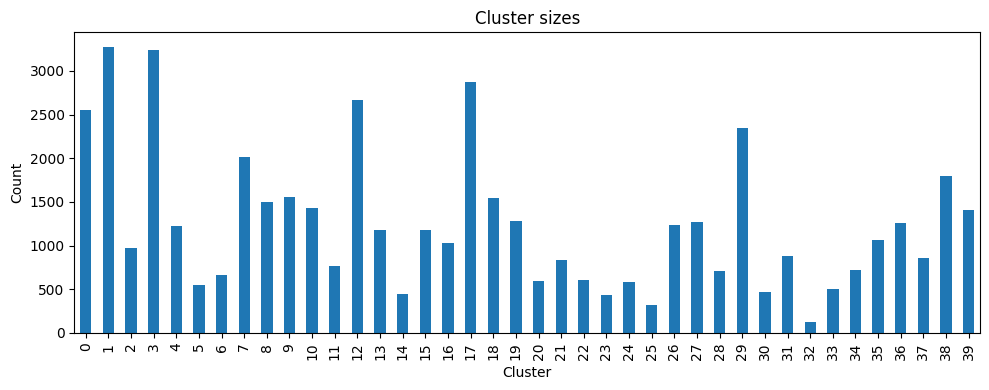

,cluster,label,n,keywords
1,1,"toy, pokemon, play, kid",3278,"toy, pokemon, play, kid, mario, surprise"
3,3,"trailer, movie, film, sony",3243,"trailer, movie, film, sony, official, picture"
17,17,"spinner, palestine, pakistan, israel",2876,"spinner, palestine, pakistan, israel, wd, narc..."
12,12,"snl, live, night, saturday",2670,"snl, live, night, saturday, saturday night, ni..."
0,0,"furulevi, tutorial, camera, battery",2553,"furulevi, furulevi tutorial, tutorial, camera,..."
29,29,"makeup, issa, rae, baldi",2349,"makeup, issa, issa rae, rae, baldi, hair"
7,7,"simulator, farming, ford, truck",2019,"simulator, farming, farming simulator, simulat..."
38,38,"snl, saturday night, night live, season",1795,"snl, snl saturday, saturday night, saturday, n..."
9,9,"snl, live, saturday night, season",1552,"snl, live, saturday night, night live, saturda..."
18,18,"reaction, julidg, tv",1546,"reaction, reaction reaction, julidg reaction, ..."


In [5]:
# cluster size plot
import matplotlib.pyplot as plt
sizes = pd.Series(labels).value_counts().sort_index()
plt.figure(figsize=(10,4))
sizes.plot(kind='bar'); plt.title("Cluster sizes"); plt.xlabel("Cluster"); plt.ylabel("Count"); plt.tight_layout(); plt.show()

# top-10 clusters table with names + keywords
tbl = (pd.DataFrame({
    "cluster": list(range(best_K)),
    "label": [cluster_name[c] for c in range(best_K)],
    "n": [int(sizes.get(c,0)) for c in range(best_K)],
    "keywords": [", ".join(cluster_keywords[c][:6]) for c in range(best_K)]
})
 .sort_values("n", ascending=False)
 .head(10))
display(tbl)


If you also want the violin by dominant cluster on your channels:

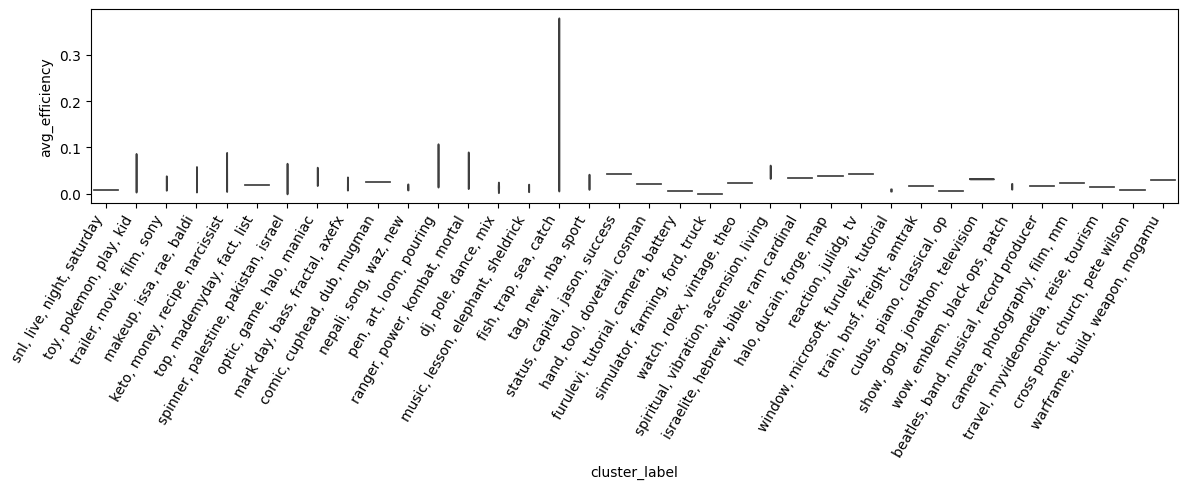

In [6]:
# predict clusters for the pilot set only (already done: labels)
# build per-channel counts → dominant cluster
pilot_df = pd.DataFrame(pilot_ids, columns=["display_id","channel_id"])
pilot_df["cluster"] = labels
dom = (pilot_df.groupby(["channel_id","cluster"]).size()
       .rename("n").reset_index()
       .sort_values(["channel_id","n"], ascending=[True,False])
       .drop_duplicates("channel_id"))

# join with your channels_final.tsv (already in your code)
channels = pd.read_csv("data/raw/channels_final.tsv", sep="\t", dtype={"channel_id":str})
df = channels.merge(dom.rename(columns={"cluster":"cluster_dom"}), on="channel_id", how="inner")
df["cluster_label"] = df["cluster_dom"].map(cluster_name)

# violin
import seaborn as sns
plt.figure(figsize=(12,5))
sns.violinplot(data=df, x="cluster_label", y="avg_efficiency", inner="quartile", cut=0)
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()


In [7]:
from scipy.stats import kruskal
g = [g['avg_efficiency'].values for _, g in df.groupby('cluster_label')]
print(kruskal(*g))


KruskalResult(statistic=np.float64(43.698943641660264), pvalue=np.float64(0.14858596153337628))
